In [1]:
import strahler
from importlib.metadata import version as package_version

package = package_version("strahler")
library = strahler.version()
if package != library:
    raise RuntimeError("Package/library version mismatch. Reinstall strahler in this kernel, "
                       "check STRAHLER_LIB, and restart the kernel before continuing.")
print("strahler package and library versions match")

from notebook_support import HERE, BACKENDS, metrics_table, table
from strahler.widgets import GameView, TreeView, Stepper
from IPython.display import display

strahler package and library versions match


# OTJ22: McNaughton–Zielonka with and without memory

## 1. Paper, definitions, and recorded steps
K. S. Thejaswini, Pierre Ohlmann, and Marcin Jurdziński,
[A Technique to Speed up Symmetric Attractor-Based Algorithms for Parity Games,
FSTTCS 2022, 44:1–44:20](https://doi.org/10.4230/LIPIcs.FSTTCS.2022.44).

Definition 3 assigns disjoint sets of vertices (the H, T, and S parts) to the
nodes of an ordered tree. Levels drop by two, and the parts must satisfy priority
bounds. Definition 1 also requires the top, side, and sequential
compositions to witness quasi-dominions. Restricting the parts can preserve a
decomposition while destroying its attractor properties.

`zielonka` implements paper Algorithm 1 (thesis Algorithm 7).
`zielonka-sym` implements paper Algorithm 2 (thesis Algorithm 8), with the
corrected entry invariant described below. Both Stepper panes contain abbreviated
pseudocode. Yellow marks the semantic block for the recorded event;
a C event can cover several pseudocode statements. Subcalls exchange players.

The C observer records events during a complete synchronous solve. The controls
navigate the recording; they do not pause C recursion. The slider includes named
event ticks; purple marks `check`. Use next call/return/check, or any event kind.
Each recorded claim shows its original step and subgame. The adjacent independent
verdict comes from a fresh `check()` on the current candidate and subgame.
A failed Definition 1 check is displayed as a decomposition candidate, with its
condition, zero-based node path, and external vertex ID. Blue outlines mark
Even AD violations; brown outlines mark Odd AD violations. Both can appear
at once on vertices, witness edges, and tree nodes. Hover gives the condition
and node. The magenta outline still marks tree hover. It does not certify
Definition 3 or imply that the current subgame is losing.

## 2. Figure 1
The supplied transcription has ten vertices a…j, all won by Even. The arrows f→e
and i→h follow the checked transcription. Even vertices are squares and Odd
vertices are pentagons, as in the paper. The linked squares and tree views below
show the same decomposition; hover over either to highlight a node in both views.
The handwritten paper tree includes empty ε₁₁; the solver prunes it and returns
five nodes. The independent verifier is `strahler.check` (there is no `verify` alias).

Handwritten paper decomposition: CheckResult(ok=True, condition=<Condition.OK: 0>, path=(), vertex=None, message='', violations=())


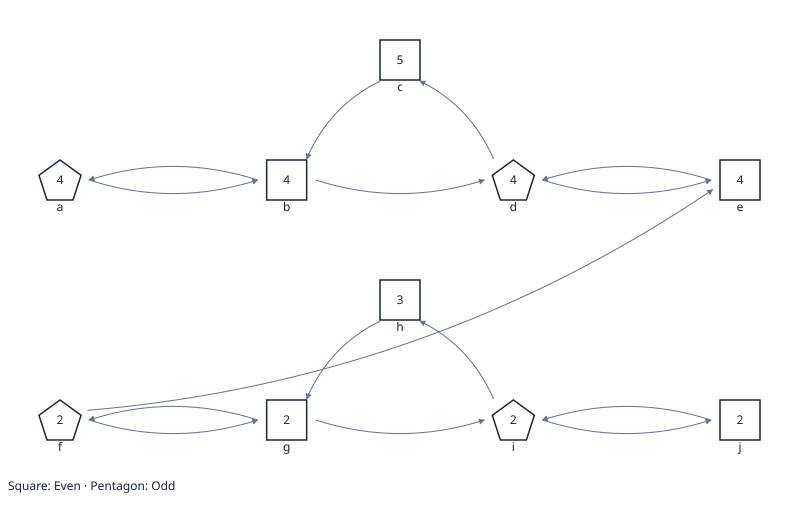

Static widget snapshot; rerun for interactive controls.

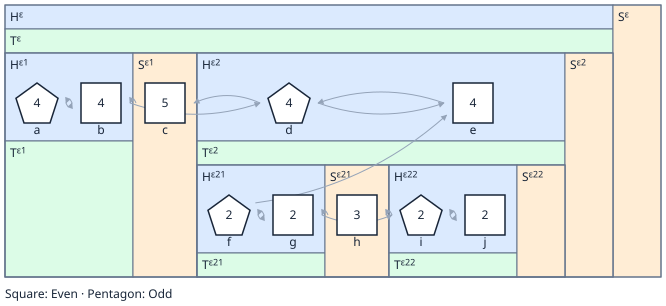

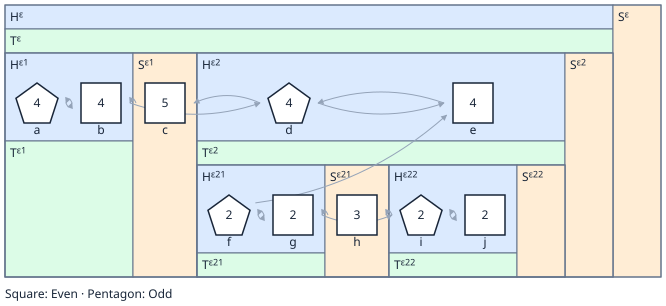

backend,player,nodes,leaves,height,Strahler,dominion,won,complete,unresolved
zielonka,Even,5,3,3,2,10,10,True,0
zielonka,Odd,0,0,0,0,0,0,True,0
zielonka-sym,Even,5,3,3,2,10,10,True,0
zielonka-sym,Odd,0,0,0,0,0,0,True,0


dominion: vertices covered by this player's attractor decomposition (its tree); won: every vertex this player wins, including vertices removed by preprocessing (+pre) or earlier shaving rounds (+iter); unresolved: vertices neither player's search certified.


In [2]:
from ipywidgets import HBox
from otj22 import hk, hk_coordinates, PAPER_FIG1, EXPECTED_CALLS, count_calls
figure = strahler.Game.from_file(HERE / "otj22-fig1.gm")
figure_results = {a: strahler.decompose(figure, a) for a in BACKENDS[:2]}
for result in figure_results.values():
    assert result.regions[0] == frozenset(figure.vertices)
    assert result.metrics["trees"][0]["nodes"] == 5
paper_verdict = strahler.check(figure, PAPER_FIG1, 0)
assert paper_verdict.ok, paper_verdict
print("Handwritten paper decomposition:", paper_verdict)
figure_view = GameView(figure)
paper_squares = TreeView(PAPER_FIG1, figure_view, mode="squares")
paper_tree = paper_squares.link(TreeView(PAPER_FIG1, figure_view, mode="tree"))
display(figure_view, HBox([paper_squares, paper_tree]))
for result in figure_results.values():
    display(TreeView(result.trees[0], figure_view))
metrics_table(figure_results)

## 3. Hₖ, laid out like Figure 2
Each row is a layer. The columns are u/v/w/x/y, with w raised. Odd-numbered layers
are won by Even and even-numbered layers by Odd. Choose k (default 4) to rebuild
both recorded algorithms and their call trees. The interactive range ends at 8
to keep recordings within the default event cap; the count experiment later runs
through k=16 using a streaming observer.

In [3]:
from ipywidgets import IntSlider, Output, VBox, HBox
from notebook_support import close_views
k_slider = IntSlider(value=4, min=1, max=8, description="k", continuous_update=False)
family_output, algorithm1_output, algorithm2_output, recursion_output = (Output() for _ in range(4))
family_views = []
def rebuild_family(change=None):
    global family, algorithm1, algorithm2, family_views
    for widget in family_views:
        close_views(widget)
    k = k_slider.value
    family = strahler.Game.from_text(hk(k))
    algorithm1 = Stepper(strahler.trace(family, "zielonka"), hk_coordinates(k))
    algorithm2 = Stepper(strahler.trace(family, "zielonka-sym"), hk_coordinates(k))
    expected_even = frozenset(v for v in family.vertices if (v // 5 + 1) % 2)
    assert algorithm1.run.result.regions[0] == algorithm2.run.result.regions[0] == expected_even
    graph = GameView(family, hk_coordinates(k))
    calls = HBox([algorithm1.call_tree(), algorithm2.call_tree()])
    family_views = [graph, algorithm1, algorithm2, calls]
    with family_output:
        family_output.clear_output(wait=True)
        display(graph)
    with algorithm1_output:
        algorithm1_output.clear_output(wait=True)
        display(algorithm1)
    with algorithm2_output:
        algorithm2_output.clear_output(wait=True)
        display(algorithm2)
    with recursion_output:
        recursion_output.clear_output(wait=True)
        display(calls)
k_slider.observe(rebuild_family, names="value")
rebuild_family()
display(VBox([k_slider, family_output]))

Static widget snapshot; rerun for interactive controls.

## 4. Algorithm 1: `zielonka`
The Algorithm 1 pane shows McNZEven/McNZOdd frames, both growing decompositions, and the
current subgame. Its coloured overlays identify Gᵢ (the subgame after earlier children's
attractors have been removed), Hᵢ, Aᵢ and U′ᵢ once those sets are recorded. Tree hover adds a magenta outline. Choose squares or a tree
independently for each player. Small, shallow decompositions start in squares. Step forward to a side attractor, then back to see
the exact previous state without rerunning the solver.

In [4]:
algorithm1.next("call")
algorithm1.next("attractor")
saved_index = algorithm1.index
saved_trees = algorithm1.state.trees
algorithm1.step()
algorithm1.back()
assert algorithm1.index == saved_index and algorithm1.state.trees == saved_trees
print("Algorithm 1 event:", algorithm1.state.event)
display(algorithm1_output)

Algorithm 1 event: {'event': 'attractor', 'step': 6, 'player': 0, 'path': [], 'kind': 'top', 'target': [17], 'vertices': [17, 18], 'subgame': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]}


Static widget snapshot; rerun for interactive controls.

## 5. Algorithm 2: `zielonka-sym`
The Algorithm 2 pane retains labels. Its `check` events show where an existing
candidate allows an early return instead of repeating calls on overlapping
subgames containing Hₖ₋₁. Claims and independent verdicts are separate observations.

At recursive calls after Set/Move, the corrected entry invariant allows the
higher player's label to lie in its core or S part (root S means TOP). Stale
children are closed to total traps by removing the escaping attractor before
recursion. This can differ from printed pseudocode; it follows the repository's
corrected entry invariant in `docs/symmetric.md`. The Stepper repeats this note
beside the highlighted block where the correction applies.

In [5]:
algorithm2.next("check")
event = algorithm2.state.event
independent = algorithm2.verify(event["player"])
assert independent.ok == event["is_attractor_decomposition"]
print("First check:", event, "Independent:", independent)
display(algorithm2_output)
# Higher-side entry example from docs/symmetric.md.
entry_game = strahler.Game.from_text('0 1 0 0; 1 0 0 1,0;')
entry_stepper = Stepper(strahler.trace(entry_game, "zielonka-sym"))
entry_stepper.next("call")
entry_stepper.next("call")
assert entry_stepper.state.event["subgame"] == [1]
display(entry_stepper)

First check: {'event': 'check', 'step': 66, 'player': 0, 'path': [], 'is_attractor_decomposition': False, 'subgame': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19], 'reason': 'restricted labelling condition fails'} Independent: CheckResult(ok=False, condition=<Condition.TOP: 5>, path=(), vertex=0, message='the stored top attractor is incorrect', violations=(Violation(condition=<Condition.TOP: 5>, path=(), vertex=0, edge=(0, 1)),))


Static widget snapshot; rerun for interactive controls.

Static widget snapshot; rerun for interactive controls.

## 6. Recursion trees and call counts
The paired call trees show the same k. Click a call (or focus it and press Enter)
to jump the corresponding Stepper there. Counts are recomputed for every even
k=2…16 and asserted against the supplied measurements. Counting uses the
documented C ABI observer without retaining all events; the ordinary Python
`trace()` keeps its recording in memory. The counts are for these games and do
not prove a general complexity bound.

In [6]:
display(recursion_output)
counts = {algorithm: [count_calls(hk(k), algorithm) for k in range(2, 17, 2)]
          for algorithm in BACKENDS[:2]}
assert counts == EXPECTED_CALLS, counts
# Cross-check the counting observer against public Python recordings on H_4.
for stepper in (algorithm1, algorithm2):
    if k_slider.value == 4:
        assert sum(e["event"] == "call" for e in stepper.run.events) == counts[stepper.run.events[0]["algorithm"]][1]
table(["k", "zielonka", "zielonka-sym"],
      zip(range(2, 17, 2), counts["zielonka"], counts["zielonka-sym"]))
from notebook_support import call_count_plot
call_count_plot(counts)

Static widget snapshot; rerun for interactive controls.

k,zielonka,zielonka-sym
2,10,7
4,50,23
6,218,47
8,898,83
10,3626,131
12,14546,191
14,58234,263
16,232994,347


## 7. Lifting on the same games
`lifting` uses the Strahler host and adaptive t. `lifting-sym` is related to paper
Algorithm 3 (thesis Algorithm 9); the implementation includes the entry correction
and final short-lift certification. Symmetric lifting does not accept adaptive
hosts. Use next lift, round_end, or phase to inspect its progress.

In [7]:
bonus = {}
for name, game in [("Figure 1", figure), ("H_4", strahler.Game.from_text(hk(4)))]:
    for backend in BACKENDS[2:]:
        options = {"adaptive_t": True} if backend == "lifting" else {}
        run = strahler.trace(game, backend, **options)
        assert run.result.complete
        bonus[f"{name}/{backend}"] = run.result
        if name == "H_4":
            display(Stepper(run, hk_coordinates(4)))
metrics_table(bonus)

Static widget snapshot; rerun for interactive controls.

Static widget snapshot; rerun for interactive controls.

backend,player,nodes,leaves,height,Strahler,dominion,won,complete,unresolved
Figure 1/lifting,Even,6,3,3,2,10,10,True,0
Figure 1/lifting,Odd,0,0,0,0,0,0,True,0
Figure 1/lifting-sym,Even,5,3,3,2,10,10,True,0
Figure 1/lifting-sym,Odd,0,0,0,0,0,0,True,0
H_4/lifting,Even,6,3,3,2,10,10,True,0
H_4/lifting,Odd,6,3,3,2,10,10,True,0
H_4/lifting-sym,Even,5,3,3,2,10,10,True,0
H_4/lifting-sym,Odd,5,3,3,2,10,10,True,0


dominion: vertices covered by this player's attractor decomposition (its tree); won: every vertex this player wins, including vertices removed by preprocessing (+pre) or earlier shaving rounds (+iter); unresolved: vertices neither player's search certified.


## 8. Your own game
Paste PGSolver text, then press "Parse and solve". This reruns both recursive
algorithms, their linked views and clickable call trees, plus all four backends'
metrics. The default example runs automatically. A trace limit is an error,
never a complete result; reduce the game or use `decompose()` without a trace
for large inputs.

In [8]:
from notebook_support import editor, comparison
def solve_own(text):
    game = strahler.Game.from_text(text)
    metrics_table({a: strahler.decompose(game, a) for a in BACKENDS})
    return comparison(text)
display(editor(hk(2), solve=solve_own))

backend,player,nodes,leaves,height,Strahler,dominion,won,complete,unresolved
zielonka,Even,3,2,2,2,5,5,True,0
zielonka,Odd,3,2,2,2,5,5,True,0
zielonka-sym,Even,3,2,2,2,5,5,True,0
zielonka-sym,Odd,3,2,2,2,5,5,True,0
lifting,Even,3,2,2,2,5,5,True,0
lifting,Odd,3,2,2,2,5,5,True,0
lifting-sym,Even,3,2,2,2,5,5,True,0
lifting-sym,Odd,3,2,2,2,5,5,True,0
